# GPS Anomaly Detection — Unsupervised Machine Learning

**Project:** GPS Digital Twin with LLM Agent — PFA iDIRTECH
**Dataset:** Porto Taxi Trajectory (ECML/PKDD 2015) — 444 taxis, 1.7M trips
**Goal:** Compare a rule-based anomaly detector against unsupervised ML models (Isolation Forest)

---

## Pipeline

```
Raw GPS pings (lat, lon)
        v
UTM projection (zone 29N) -> meters
        v
Kalman filter per taxi -> [x, y, vx, vy]
        v
Feature extraction (6 features per ping)
        v
Isolation Forest (unsupervised)
        v
Comparison vs rule-based detector
```

## 1. Setup

In [2]:
!pip install filterpy pyproj -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 3.8 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pyproj import Proj
from ast import literal_eval
from tqdm import tqdm
from filterpy.kalman import KalmanFilter

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries loaded")

Libraries loaded


## 2. Kalman Filter

Same implementation as the production pipeline (`twin/kalman_filter.py`).

- State vector: `[x, y, vx, vy]` — position and velocity in UTM meters
- Constant-velocity motion model, `dt = 15s` (Porto ping interval)
- `R = 9.0` — GPS measurement noise (~3m std dev)
- `Q = 0.01` — process noise, tuned for smooth velocity estimates
- `P = 500` — initial uncertainty

In [4]:
def create_vehicle_filter(dt: float = 15.0) -> KalmanFilter:
    """
    Create a Kalman filter for vehicle tracking.

    Parameters:
        dt (float): Time step in seconds. Default 15.0 (Porto ping interval).

    Returns:
        KalmanFilter: Configured Kalman filter instance.
    """
    kf = KalmanFilter(dim_x=4, dim_z=2)

    # State transition — constant velocity model
    kf.F = np.array([[1, 0, dt, 0],
                     [0, 1, 0, dt],
                     [0, 0, 1,  0],
                     [0, 0, 0,  1]])

    # Measurement matrix — GPS observes position only
    kf.H = np.array([[1, 0, 0, 0],
                     [0, 1, 0, 0]])

    kf.R = np.eye(2) * 9.0      # GPS noise ~3m std dev -> variance 9
    kf.P = np.eye(4) * 500.0    # initial uncertainty
    kf.Q = np.eye(4) * 0.01     # process noise
    kf.x = np.zeros((4, 1))     # initial state
    return kf


class VehicleTwin:
    """Digital twin for one vehicle — wraps a Kalman filter."""

    def __init__(self, taxi_id: str):
        self.taxi_id = taxi_id
        self.kf = create_vehicle_filter()
        self.initialized = False
        self.last_x = None
        self.last_y = None

    def update(self, x: float, y: float) -> dict:
        """
        Run one predict-update cycle with a new GPS measurement.

        Parameters:
            x (float): Easting in UTM meters.
            y (float): Northing in UTM meters.

        Returns:
            dict: Filtered state estimate.
        """
        if not self.initialized:
            self.kf.x = np.array([[x], [y], [0], [0]])
            self.initialized = True
        else:
            self.kf.predict()
            self.kf.update(np.array([[x], [y]]))

        prev_x, prev_y = self.last_x, self.last_y
        self.last_x = float(self.kf.x[0])
        self.last_y = float(self.kf.x[1])

        return {
            "taxi_id": self.taxi_id,
            "x": float(self.kf.x[0]),
            "y": float(self.kf.x[1]),
            "vx": float(self.kf.x[2]),
            "vy": float(self.kf.x[3]),
            "speed": float(np.sqrt(self.kf.x[2]**2 + self.kf.x[3]**2)),
            "uncertainty": float(np.trace(self.kf.P)),
            "prev_x": prev_x,
            "prev_y": prev_y
        }

print("Kalman filter defined")

Kalman filter defined


## 3. UTM Projection

The Kalman filter operates in Euclidean space. GPS coordinates in degrees are not metric — 1 degree of longitude is ~84km at Porto's latitude but ~111km at the equator. UTM zone 29N converts lat/lon to meters so distances and velocities are physically meaningful.

In [5]:
UTM_ZONE = Proj(proj="utm", zone=29, ellps="WGS84")

def latlon_to_meters(lat: float, lon: float) -> tuple:
    """
    Convert WGS84 lat/lon to UTM zone 29N coordinates in meters.

    Parameters:
        lat (float): Latitude in decimal degrees.
        lon (float): Longitude in decimal degrees.

    Returns:
        tuple: (x, y) in meters.
    """
    x, y = UTM_ZONE(lon, lat)   # pyproj expects (lon, lat)
    return x, y

# sanity check
print(latlon_to_meters(41.148, -8.610))

(532726.1536538537, 4555259.966858393)


## 4. Load & Clean Dataset

Filters applied:
- Remove trips flagged `MISSING_DATA = True`
- Remove trips with empty POLYLINE
- Parse POLYLINE string into a Python list of `[lon, lat]` pairs

In [6]:
DATA_PATH = "/kaggle/input/datasets/abdeljalilnahimy/taxi-trajectory/train.csv"

df = pd.read_csv(DATA_PATH, usecols=["TAXI_ID", "MISSING_DATA", "POLYLINE"])

df = df[df["MISSING_DATA"] == False]
df = df[df["POLYLINE"] != "[]"]
df = df.drop(columns=["MISSING_DATA"])
df["POLYLINE"] = df["POLYLINE"].apply(literal_eval)

print(f"Total trips: {len(df):,}")
print(f"Total taxis: {df['TAXI_ID'].nunique()}")
print(f"Sample POLYLINE: {df['POLYLINE'].iloc[0][:3]}")

Total trips: 1,704,759
Total taxis: 444
Sample POLYLINE: [[-8.618643, 41.141412], [-8.618499, 41.141376], [-8.620326, 41.14251]]


## 5. Feature Extraction

For each taxi, a fresh Kalman filter processes every ping of every trip sequentially.
`prev_x` / `prev_y` reset at the start of each trip — the gap between the last ping of one
trip and the first ping of the next is not a real position jump.

The first ping per taxi is skipped: at that point the filter is still initialising
(`uncertainty = 2000`, `speed = 0`) and those values are artefacts, not measurements.

**Scope:** 200 trips per taxi. All 444 taxis are represented while keeping runtime
tractable (~6 min vs ~2h for the full 83M-ping dataset). For an unsupervised model,
4.3M samples is well past the point where additional data shifts the decision boundary.

In [7]:
TRIPS_PER_TAXI = 200

df_sample = df.groupby("TAXI_ID").head(TRIPS_PER_TAXI).reset_index(drop=True)
print(f"Trips selected: {len(df_sample):,}")

all_features = []

for taxi_id, taxi_trips in tqdm(df_sample.groupby("TAXI_ID"), desc="Processing taxis"):
    twin = VehicleTwin(str(int(taxi_id)))

    for _, trip in taxi_trips.iterrows():
        prev_x, prev_y = None, None   # reset per trip

        for lon, lat in trip["POLYLINE"]:
            x, y = latlon_to_meters(lat, lon)
            state = twin.update(x, y)

            jump = 0.0
            if prev_x is not None:
                jump = np.sqrt((state["x"] - prev_x)**2 + (state["y"] - prev_y)**2)

            # skip first ping per taxi — filter not initialised
            if state["prev_x"] is not None:
                all_features.append({
                    "taxi_id": taxi_id,
                    "speed": state["speed"],
                    "vx": state["vx"],
                    "vy": state["vy"],
                    "uncertainty": state["uncertainty"],
                    "jump_distance": jump
                })

            prev_x, prev_y = state["x"], state["y"]

feat_df = pd.DataFrame(all_features)

# temporal context features
feat_df["rolling_mean_speed"] = feat_df.groupby("taxi_id")["speed"].transform(
    lambda s: s.rolling(5, min_periods=1).mean()
)
feat_df["rolling_std_speed"] = feat_df.groupby("taxi_id")["speed"].transform(
    lambda s: s.rolling(5, min_periods=1).std().fillna(0)
)

feat_df.to_csv("/kaggle/working/porto_features.csv", index=False)

print(f"\nTotal pings: {len(feat_df):,}")
print(f"Columns: {feat_df.columns.tolist()}")
feat_df.head()

Trips selected: 87,573


Processing taxis: 100%|██████████| 444/444 [06:09<00:00,  1.20it/s]



Total pings: 4,311,098
Columns: ['taxi_id', 'speed', 'vx', 'vy', 'uncertainty', 'jump_distance', 'rolling_mean_speed', 'rolling_std_speed']


,taxi_id,speed,vx,vy,uncertainty,jump_distance,rolling_mean_speed,rolling_std_speed
0,20000001,5.377567,-5.205093,-1.351013,22.522721,81.022019,5.377567,0.000000
1,20000001,12.975293,-12.098592,4.688529,17.870913,199.116819,9.176430,5.372403
2,20000001,11.181125,-10.362825,4.198742,15.057833,150.686135,9.844662,3.971267
3,20000001,6.919200,-6.415520,2.591609,13.114579,37.993158,9.113296,3.557184
4,20000001,3.755060,-3.489847,1.386163,12.085720,1.519105,8.041649,3.902859


### Feature reference

| Feature | Source | Signal captured |
|---|---|---|
| `speed` | `sqrt(vx^2 + vy^2)` from Kalman | velocity magnitude |
| `vx` | Kalman state `x[2]` | East-West velocity |
| `vy` | Kalman state `x[3]` | North-South velocity |
| `uncertainty` | `trace(P)` | filter confidence |
| `jump_distance` | distance from previous ping | position teleportation |
| `rolling_mean_speed` | mean speed, window 5 | driving baseline for this taxi |
| `rolling_std_speed` | std speed, window 5 | erratic driving |

The rolling features add temporal context that threshold rules cannot express: 50 m/s
is unremarkable on a highway but highly suspicious if the previous five pings averaged 5 m/s.

## 6. Exploratory Analysis

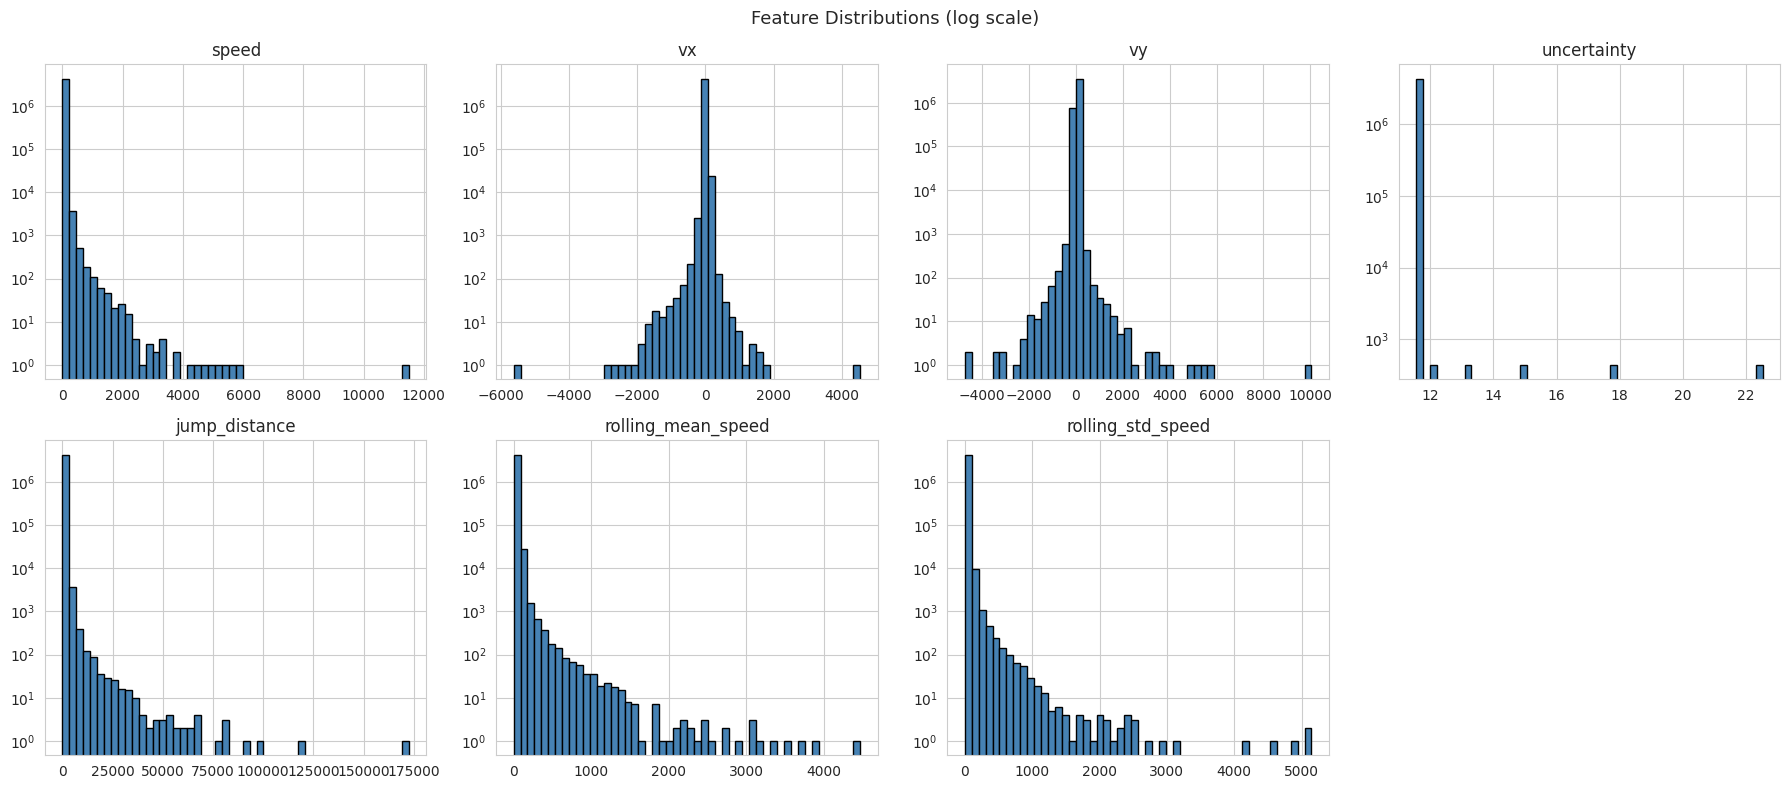

,speed,vx,vy,uncertainty,jump_distance,rolling_mean_speed,rolling_std_speed
count,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06,4.311098e+06
mean,1.089980e+01,-4.926616e-03,1.666560e-03,1.155490e+01,1.500875e+02,1.089962e+01,5.356324e+00
std,2.546937e+01,1.716879e+01,2.174230e+01,1.341781e-01,3.635448e+02,1.962464e+01,1.734284e+01
min,0.000000e+00,-5.619934e+03,-4.734827e+03,1.155254e+01,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.887274e+00,-3.581226e+00,-2.526927e+00,1.155254e+01,3.261753e+01,3.724957e+00,1.010481e+00
50%,6.302837e+00,3.795683e-04,6.476940e-02,1.155254e+01,9.636698e+01,6.840830e+00,1.902205e+00
75%,1.127812e+01,3.359001e+00,3.452962e+00,1.155254e+01,1.776007e+02,1.193562e+01,3.622049e+00
max,1.151308e+04,4.541626e+03,1.004825e+04,2.252272e+01,1.726669e+05,4.471348e+03,5.146486e+03


In [8]:
all_feats = ["speed", "vx", "vy", "uncertainty",
             "jump_distance", "rolling_mean_speed", "rolling_std_speed"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, feat in enumerate(all_feats):
    ax = axes[i // 4, i % 4]
    feat_df[feat].hist(bins=50, ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(feat)
    ax.set_yscale("log")

axes[1, 3].axis("off")
plt.suptitle("Feature Distributions (log scale)", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

feat_df[all_feats].describe()

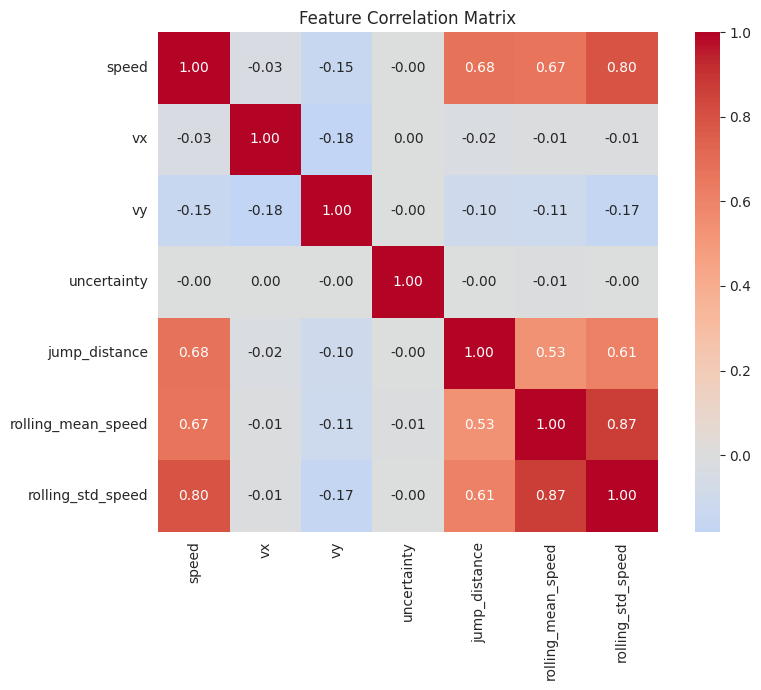

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(feat_df[all_feats].corr(), annot=True, cmap="coolwarm",
            fmt=".2f", center=0, square=True)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA findings

**Extreme outliers confirm documented GPS noise**
- Max speed ~11,500 m/s (~41,000 km/h) — physically impossible
- Max jump distance ~172 km in a single 15-second interval
- Median speed 6.3 m/s (~23 km/h) and median jump 96 m are entirely realistic

This matches the ECML/PKDD 2015 challenge documentation, which notes that many GPS points
in this dataset fall outside the road network and require noise correction.

**`uncertainty` is dropped from the model**
Std = 0.13 across 4.3M rows and correlation ~0.00 with every other feature. The Kalman
filter converges to the same steady-state covariance for every taxi, so this column
carries no discriminative information.

**Final feature set: 6 features.**

In [10]:
features = ["speed", "vx", "vy", "jump_distance",
            "rolling_mean_speed", "rolling_std_speed"]

print(f"Model features ({len(features)}): {features}")

Model features (6): ['speed', 'vx', 'vy', 'jump_distance', 'rolling_mean_speed', 'rolling_std_speed']


## 7. Isolation Forest

Unsupervised outlier detection. The algorithm builds random trees that recursively split
the feature space; anomalies require fewer splits to isolate because they sit in sparse
regions. No labels are required.

`contamination=0.03` — the expected anomaly rate, chosen from the EDA distributions.

In [11]:
X = feat_df[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

feat_df["iso_pred"]    = iso.fit_predict(X_scaled)
feat_df["iso_anomaly"] = feat_df["iso_pred"] == -1
feat_df["iso_score"]   = iso.score_samples(X_scaled)

n_anom = feat_df["iso_anomaly"].sum()
print(f"Anomalies detected: {n_anom:,} ({feat_df['iso_anomaly'].mean()*100:.2f}%)")

Anomalies detected: 129,333 (3.00%)


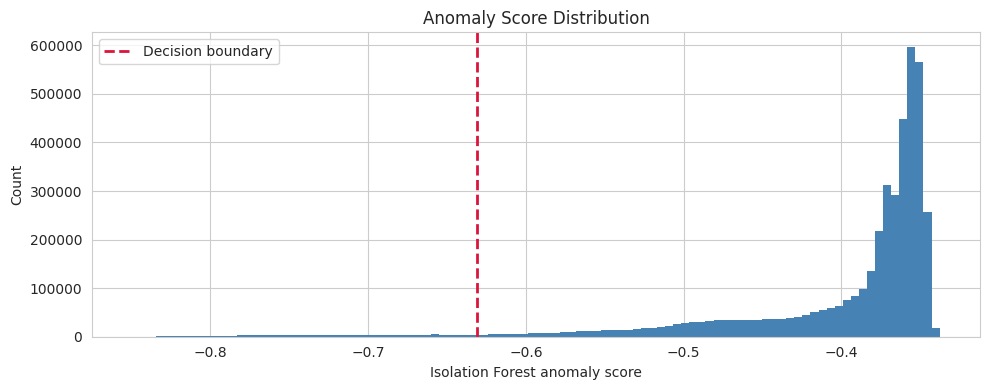

In [12]:
plt.figure(figsize=(10, 4))
plt.hist(feat_df["iso_score"], bins=100, color="steelblue", edgecolor="none")
plt.axvline(feat_df[feat_df["iso_anomaly"]]["iso_score"].max(),
            color="crimson", linestyle="--", linewidth=2, label="Decision boundary")
plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("Count")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/anomaly_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Comparison vs Rule-Based Detector

The production detector uses fixed thresholds, tuned earlier via an F1 sweep on synthetic
anomaly injection:

- `speed > 80 m/s` -> speed anomaly
- `jump_distance > 800 m` -> position jump

No manually labelled ground truth exists for this dataset, so the rule-based output is used
as a **pseudo ground truth** reference. Metrics measure agreement between the two methods,
not absolute correctness.

In [13]:
SPEED_THRESHOLD = 80.0
JUMP_THRESHOLD  = 800.0

feat_df["rule_anomaly"] = (
    (feat_df["speed"] > SPEED_THRESHOLD) |
    (feat_df["jump_distance"] > JUMP_THRESHOLD)
)

print(f"Rule-based anomalies:      {feat_df['rule_anomaly'].sum():,} "
      f"({feat_df['rule_anomaly'].mean()*100:.2f}%)")
print(f"Isolation Forest anomalies: {feat_df['iso_anomaly'].sum():,} "
      f"({feat_df['iso_anomaly'].mean()*100:.2f}%)")

both      = ((feat_df["rule_anomaly"])  & (feat_df["iso_anomaly"])).sum()
only_rule = ((feat_df["rule_anomaly"])  & (~feat_df["iso_anomaly"])).sum()
only_iso  = ((~feat_df["rule_anomaly"]) & (feat_df["iso_anomaly"])).sum()
neither   = ((~feat_df["rule_anomaly"]) & (~feat_df["iso_anomaly"])).sum()

print("\nAgreement matrix:")
print(f"  Both flagged:          {both:,}")
print(f"  Only rule-based:       {only_rule:,}")
print(f"  Only Isolation Forest: {only_iso:,}")
print(f"  Neither:               {neither:,}")
print(f"\nRule-based anomalies also caught by IF: {both/feat_df['rule_anomaly'].sum()*100:.1f}%")

Rule-based anomalies:      81,424 (1.89%)
Isolation Forest anomalies: 129,333 (3.00%)

Agreement matrix:
  Both flagged:          78,195
  Only rule-based:       3,229
  Only Isolation Forest: 51,138
  Neither:               4,178,536

Rule-based anomalies also caught by IF: 96.0%


Isolation Forest vs rule-based (full dataset, in-sample)

              precision    recall  f1-score   support

      Normal      0.999     0.988     0.994   4229674
     Anomaly      0.605     0.960     0.742     81424

    accuracy                          0.987   4311098
   macro avg      0.802     0.974     0.868   4311098
weighted avg      0.992     0.987     0.989   4311098



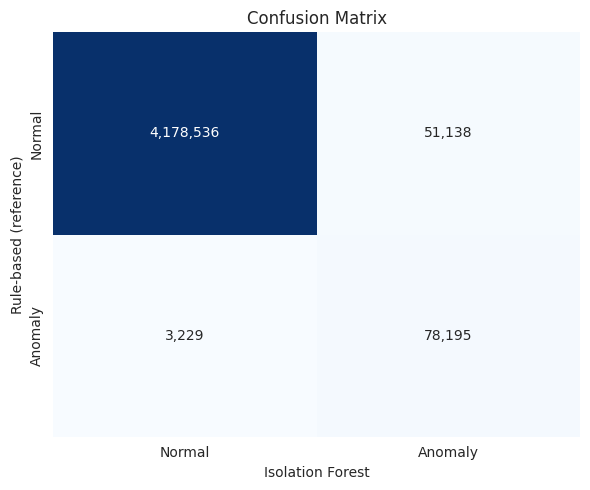

In [14]:
y_true = feat_df["rule_anomaly"].astype(int)
y_pred = feat_df["iso_anomaly"].astype(int)

print("Isolation Forest vs rule-based (full dataset, in-sample)\n")
print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"], digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Anomaly"],
            yticklabels=["Normal", "Anomaly"])
plt.xlabel("Isolation Forest")
plt.ylabel("Rule-based (reference)")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cross-Validation

5-fold **GroupKFold, grouped by taxi**. Consecutive pings from the same vehicle are highly
correlated — random row-level splitting would leak information between folds and inflate
the metrics. Grouping by taxi guarantees every fold is evaluated on vehicles the model has
never seen.

The scaler is fitted on the training fold only and applied to the test fold, so no test
statistics leak into preprocessing.

In [15]:
gkf = GroupKFold(n_splits=5)

X_all  = feat_df[features].fillna(0).values
groups = feat_df["taxi_id"].values

results = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_all, groups=groups), 1):
    X_train, X_test = X_all[train_idx], X_all[test_idx]

    fold_scaler = StandardScaler()
    X_train_scaled = fold_scaler.fit_transform(X_train)
    X_test_scaled  = fold_scaler.transform(X_test)

    fold_iso = IsolationForest(contamination=0.03, n_estimators=100,
                               random_state=42, n_jobs=-1)
    fold_iso.fit(X_train_scaled)

    y_pred_fold = fold_iso.predict(X_test_scaled) == -1

    test_data = feat_df.iloc[test_idx]
    y_rule_fold = ((test_data["speed"] > SPEED_THRESHOLD) |
                   (test_data["jump_distance"] > JUMP_THRESHOLD))

    results.append({
        "fold": fold,
        "train_taxis": len(np.unique(groups[train_idx])),
        "test_taxis": len(np.unique(groups[test_idx])),
        "test_pings": len(test_idx),
        "anomaly_rate_%": round(y_pred_fold.mean() * 100, 2),
        "precision": precision_score(y_rule_fold, y_pred_fold),
        "recall": recall_score(y_rule_fold, y_pred_fold),
        "f1": f1_score(y_rule_fold, y_pred_fold)
    })

    print(f"Fold {fold}: {len(test_idx):>9,} pings | "
          f"{results[-1]['test_taxis']:>3} taxis | "
          f"P={results[-1]['precision']:.3f} "
          f"R={results[-1]['recall']:.3f} "
          f"F1={results[-1]['f1']:.3f}")

cv_df = pd.DataFrame(results)
cv_df.to_csv("/kaggle/working/cv_results.csv", index=False)

print("\n" + "=" * 70)
print("CROSS-VALIDATION SUMMARY (5-fold, grouped by taxi)")
print("=" * 70)
print(cv_df.to_string(index=False))
print(f"\nMean F1:        {cv_df['f1'].mean():.3f} +/- {cv_df['f1'].std():.3f}")
print(f"Mean Precision: {cv_df['precision'].mean():.3f} +/- {cv_df['precision'].std():.3f}")
print(f"Mean Recall:    {cv_df['recall'].mean():.3f} +/- {cv_df['recall'].std():.3f}")

Fold 1:   862,343 pings |  87 taxis | P=0.600 R=0.950 F1=0.736
Fold 2:   862,380 pings |  87 taxis | P=0.604 R=0.958 F1=0.741
Fold 3:   862,116 pings |  90 taxis | P=0.603 R=0.961 F1=0.741
Fold 4:   862,381 pings |  88 taxis | P=0.599 R=0.948 F1=0.734
Fold 5:   861,878 pings |  91 taxis | P=0.603 R=0.954 F1=0.739

CROSS-VALIDATION SUMMARY (5-fold, grouped by taxi)
 fold  train_taxis  test_taxis  test_pings  anomaly_rate_%  precision   recall       f1
    1          356          87      862343            2.93   0.600111 0.949781 0.735501
    2          356          87      862380            2.98   0.604295 0.957808 0.741051
    3          353          90      862116            3.20   0.602938 0.961089 0.741007
    4          355          88      862381            2.93   0.599232 0.948212 0.734371
    5          352          91      861878            2.93   0.603357 0.953758 0.739131

Mean F1:        0.738 +/- 0.003
Mean Precision: 0.602 +/- 0.002
Mean Recall:    0.954 +/- 0.005


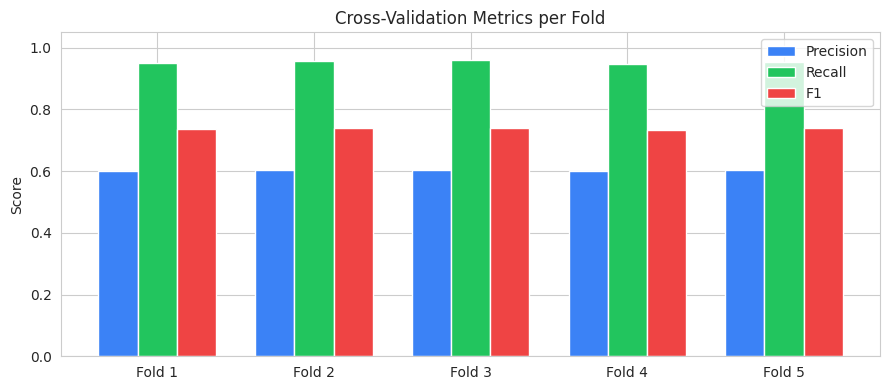

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cv_df))
w = 0.25

ax.bar(x - w, cv_df["precision"], w, label="Precision", color="#3b82f6")
ax.bar(x,     cv_df["recall"],    w, label="Recall",    color="#22c55e")
ax.bar(x + w, cv_df["f1"],        w, label="F1",        color="#ef4444")

ax.set_xticks(x)
ax.set_xticklabels([f"Fold {i}" for i in cv_df["fold"]])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Cross-Validation Metrics per Fold")
ax.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/cv_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. What Does Isolation Forest Catch That Rules Miss?

The most interesting group is the pings flagged by Isolation Forest but not by any threshold.
These are cases where no single feature is extreme, but the *combination* is unusual —
exactly what one-dimensional rules cannot express.

In [17]:
only_iso_df = feat_df[(~feat_df["rule_anomaly"]) & (feat_df["iso_anomaly"])]
normal_df   = feat_df[(~feat_df["rule_anomaly"]) & (~feat_df["iso_anomaly"])]

print(f"Flagged by Isolation Forest only: {len(only_iso_df):,}\n")

comparison_stats = pd.DataFrame({
    "IF-only anomaly (mean)": only_iso_df[features].mean(),
    "Normal (mean)":          normal_df[features].mean(),
    "Ratio":                  only_iso_df[features].mean() / normal_df[features].mean()
})
comparison_stats.round(2)

Flagged by Isolation Forest only: 51,138



,IF-only anomaly (mean),Normal (mean),Ratio
speed,46.80,8.32,5.62
vx,5.58,-0.34,-16.25
vy,-5.87,0.74,-7.98
jump_distance,299.51,124.89,2.40
rolling_mean_speed,71.72,9.09,7.89
rolling_std_speed,53.43,3.51,15.21


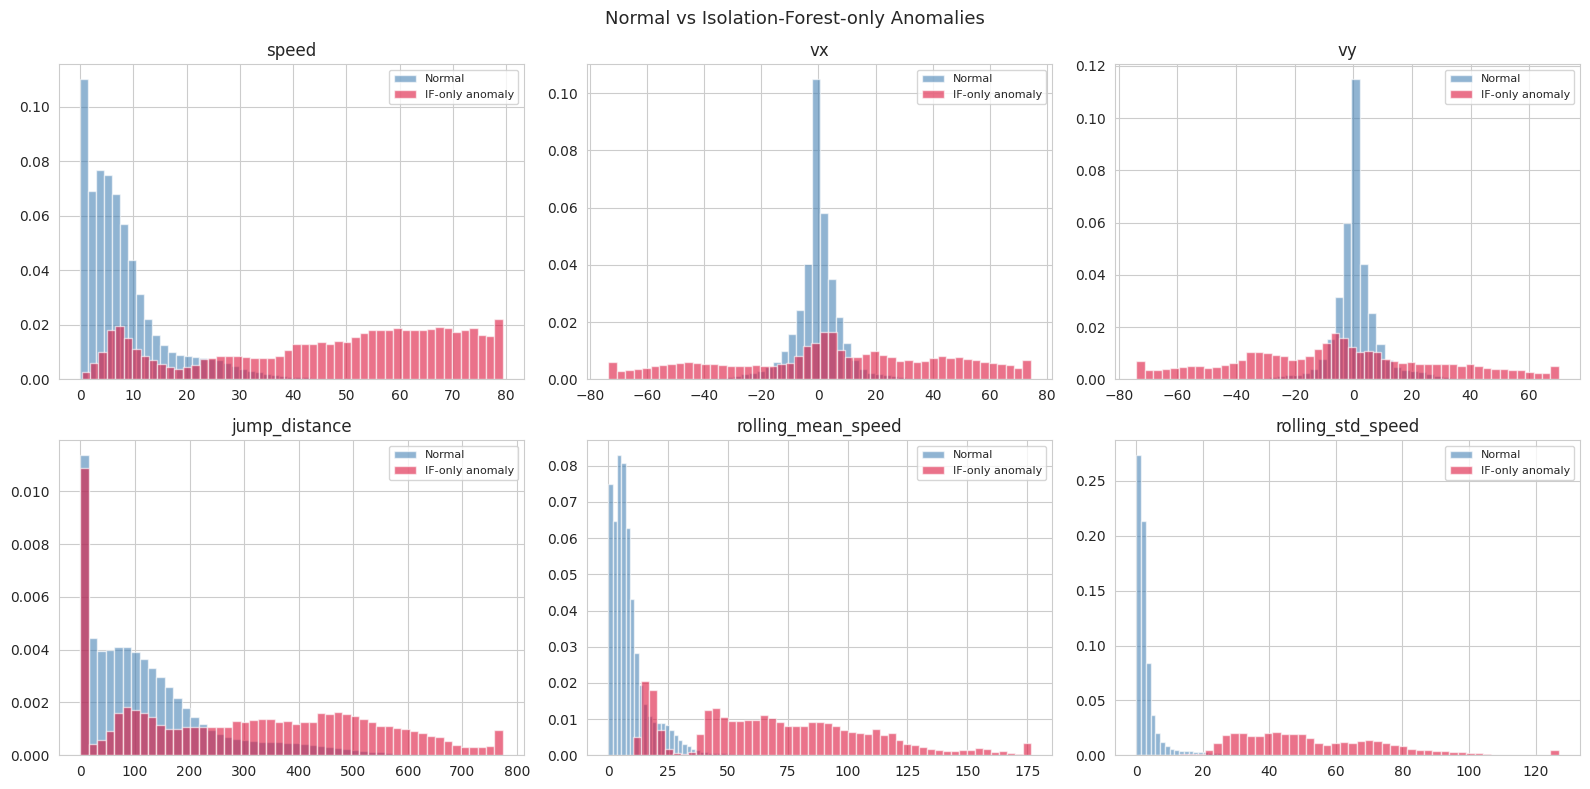

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, feat in enumerate(features):
    ax = axes[i // 3, i % 3]
    hi = max(normal_df[feat].quantile(0.99), only_iso_df[feat].quantile(0.99))
    lo = min(normal_df[feat].quantile(0.01), only_iso_df[feat].quantile(0.01))

    ax.hist(normal_df[feat].clip(lo, hi), bins=50, alpha=0.6,
            label="Normal", color="steelblue", density=True)
    ax.hist(only_iso_df[feat].clip(lo, hi), bins=50, alpha=0.6,
            label="IF-only anomaly", color="crimson", density=True)
    ax.set_title(feat)
    ax.legend(fontsize=8)

plt.suptitle("Normal vs Isolation-Forest-only Anomalies", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/if_only_anomalies.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Feature Importance

Permutation importance: each feature is shuffled in turn and the mean anomaly score shift is measured. Larger shift = feature contributes more to the decision.

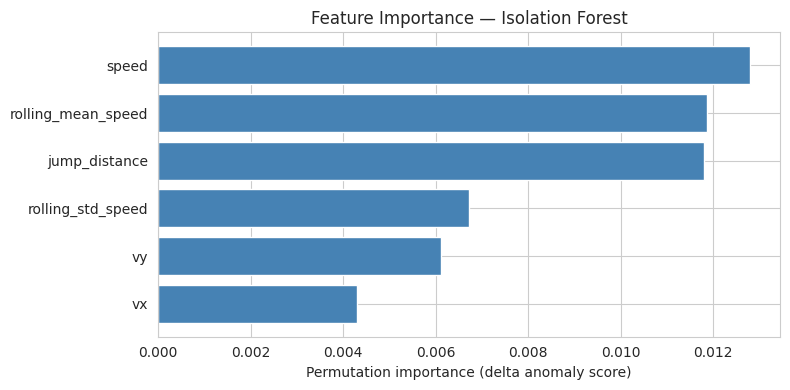

,feature,importance
0,speed,0.012806
1,rolling_mean_speed,0.011870
2,jump_distance,0.011793
3,rolling_std_speed,0.006723
4,vy,0.006105
5,vx,0.004292


In [19]:
baseline = iso.score_samples(X_scaled).mean()
importances = {}

rng = np.random.default_rng(42)
for i, feat in enumerate(features):
    X_shuffled = X_scaled.copy()
    rng.shuffle(X_shuffled[:, i])
    importances[feat] = abs(baseline - iso.score_samples(X_shuffled).mean())

imp_df = (pd.DataFrame(importances.items(), columns=["feature", "importance"])
            .sort_values("importance", ascending=False)
            .reset_index(drop=True))

plt.figure(figsize=(8, 4))
plt.barh(imp_df["feature"], imp_df["importance"], color="steelblue")
plt.xlabel("Permutation importance (delta anomaly score)")
plt.title("Feature Importance — Isolation Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("/kaggle/working/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

imp_df

## 12. Per-Taxi Anomaly Analysis

Top 15 most anomalous taxis (Isolation Forest):
 taxi_id  pings  iso_anomalies  iso_rate_%  rule_rate_%  mean_speed  mean_jump
20000276  10778            667        6.19         3.78   15.750976 216.555254
20000657   9540            577        6.05         3.62   16.622373 221.222040
20000231   6825            404        5.92         3.71   15.030459 201.595393
20000477   9917            583        5.88         3.46   16.818821 221.925358
20000534  14957            846        5.66         3.42   17.892588 245.878484
20000263   8981            502        5.59         3.60   16.800247 224.771756
20000334  10464            553        5.28         3.28   16.715694 227.146509
20000273   6893            355        5.15         3.12   15.674554 208.039194
20000525   9054            456        5.04         3.17   13.924089 189.883562
20000199  10455            527        5.04         3.30   15.426012 215.218025
20000003   7771            391        5.03         2.97   15.658910 204.977069
2000

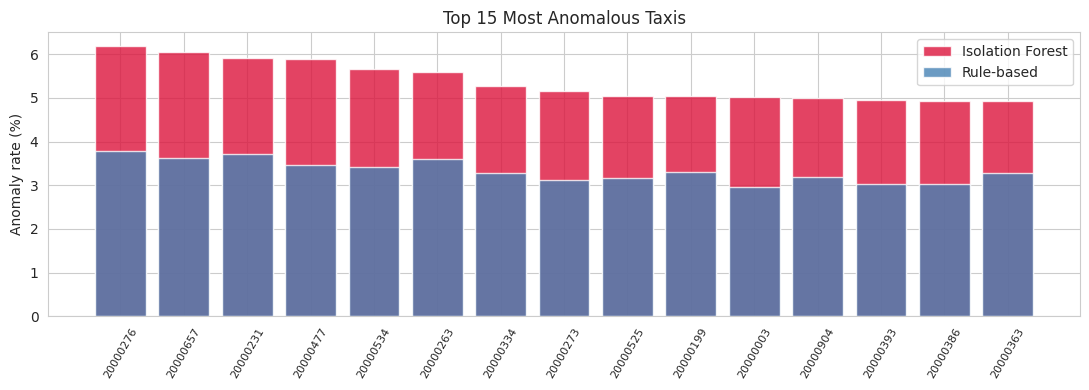

In [20]:
taxi_stats = feat_df.groupby("taxi_id").agg(
    pings=("speed", "size"),
    iso_anomalies=("iso_anomaly", "sum"),
    rule_anomalies=("rule_anomaly", "sum"),
    mean_speed=("speed", "mean"),
    mean_jump=("jump_distance", "mean")
).reset_index()

taxi_stats["iso_rate_%"]  = (taxi_stats["iso_anomalies"] / taxi_stats["pings"] * 100).round(2)
taxi_stats["rule_rate_%"] = (taxi_stats["rule_anomalies"] / taxi_stats["pings"] * 100).round(2)

worst = taxi_stats.sort_values("iso_rate_%", ascending=False).head(15)
print("Top 15 most anomalous taxis (Isolation Forest):")
print(worst[["taxi_id", "pings", "iso_anomalies", "iso_rate_%",
             "rule_rate_%", "mean_speed", "mean_jump"]].to_string(index=False))

plt.figure(figsize=(11, 4))
plt.bar(range(len(worst)), worst["iso_rate_%"], color="crimson", alpha=0.8, label="Isolation Forest")
plt.bar(range(len(worst)), worst["rule_rate_%"], color="steelblue", alpha=0.8, label="Rule-based")
plt.xticks(range(len(worst)), worst["taxi_id"].astype(str), rotation=60, fontsize=8)
plt.ylabel("Anomaly rate (%)")
plt.title("Top 15 Most Anomalous Taxis")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/worst_taxis.png", dpi=150, bbox_inches="tight")
plt.show()

taxi_stats.to_csv("/kaggle/working/taxi_anomaly_stats.csv", index=False)

In [21]:
print(taxi_stats[["mean_speed", "mean_jump", "iso_rate_%", "rule_rate_%"]].corr())

             mean_speed  mean_jump  iso_rate_%  rule_rate_%
mean_speed     1.000000   0.991878    0.872682     0.878606
mean_jump      0.991878   1.000000    0.842547     0.859416
iso_rate_%     0.872682   0.842547    1.000000     0.985582
rule_rate_%    0.878606   0.859416    0.985582     1.000000


## 13. Diagnosing the Speed Confound

The per-taxi analysis revealed a problem: a vehicle's anomaly rate correlates strongly
with its average speed (r = 0.87). This means both detectors are largely surfacing
**fast-driving vehicles** rather than **faulty GPS hardware**.

The mechanism is arithmetic. `jump_distance ≈ speed × 15s`, so `mean_speed` and
`mean_jump` are 0.992 correlated. A vehicle that habitually drives fast produces large
jump distances by definition, crossing absolute thresholds more often regardless of
sensor quality.

**Hypothesis:** replacing absolute features with per-vehicle normalised features should
reduce this confound. Instead of asking *"is this ping fast?"*, the model asks *"is this
ping fast **for this vehicle**?"*

| Absolute feature | Normalised equivalent | Interpretation |
|---|---|---|
| `speed` | `speed_z` | standard deviations from this taxi's own mean |
| `jump_distance` | `jump_z` | standard deviations from this taxi's own mean |
| — | `speed_ratio` | current speed ÷ recent 5-ping average |
| `rolling_std_speed` | `rolling_std_ratio` | variance relative to this taxi's typical variance |

`rolling_std_ratio` is included because raw variance is itself speed-dependent — leaving
it unnormalised would reintroduce the confound through the back door.

In [24]:
# ── Per-vehicle normalised features ────────────────────────────────────────
# Absolute features conflate "fast vehicle" with "faulty sensor" because
# jump_distance ≈ speed × 15s (r = 0.992). Normalising each ping against its
# own vehicle's baseline asks "unusual for THIS taxi?" rather than
# "unusual for the fleet?".

eps = 1e-6

feat_df["speed_z"] = feat_df.groupby("taxi_id")["speed"].transform(
    lambda s: (s - s.mean()) / (s.std() + eps)
)
feat_df["jump_z"] = feat_df.groupby("taxi_id")["jump_distance"].transform(
    lambda s: (s - s.mean()) / (s.std() + eps)
)
feat_df["speed_ratio"] = feat_df["speed"] / (feat_df["rolling_mean_speed"] + eps)
feat_df["rolling_std_ratio"] = feat_df["rolling_std_speed"] / (
    feat_df.groupby("taxi_id")["rolling_std_speed"].transform("mean") + eps
)

features_norm = ["speed_z", "jump_z", "speed_ratio",
                 "rolling_std_ratio", "vx", "vy"]

X_norm = feat_df[features_norm].replace([np.inf, -np.inf], np.nan).fillna(0)
scaler_norm = StandardScaler()
X_norm_scaled = scaler_norm.fit_transform(X_norm)

iso_norm = IsolationForest(contamination=0.03, n_estimators=100,
                           random_state=42, n_jobs=-1)
feat_df["iso_norm_anomaly"] = iso_norm.fit_predict(X_norm_scaled) == -1

print(f"Normalised-model anomalies: {feat_df['iso_norm_anomaly'].sum():,} "
      f"({feat_df['iso_norm_anomaly'].mean()*100:.2f}%)")

Normalised-model anomalies: 129,333 (3.00%)


Correlation between a taxi's mean speed and its anomaly rate
(closer to 0 = less confounded by driving profile)

  Rule-based:            r = +0.879
  IF, absolute features: r = +0.873
  IF, normalised:        r = +0.477

  Confound reduction: 45.4%


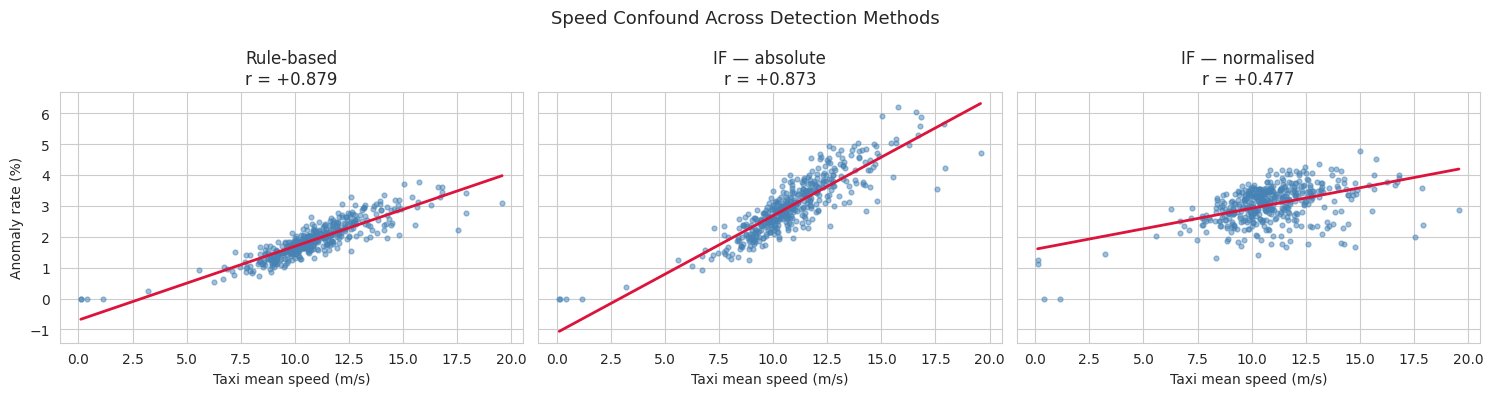

In [26]:
# ── Did normalisation remove the speed confound? ───────────────────────────
taxi_cmp = feat_df.groupby("taxi_id").agg(
    pings=("speed", "size"),
    mean_speed=("speed", "mean"),
    rate_abs=("iso_anomaly", "mean"),
    rate_norm=("iso_norm_anomaly", "mean"),
    rate_rule=("rule_anomaly", "mean")
).reset_index()

for c in ["rate_abs", "rate_norm", "rate_rule"]:
    taxi_cmp[c] *= 100

r_abs  = taxi_cmp[["mean_speed", "rate_abs"]].corr().iloc[0, 1]
r_norm = taxi_cmp[["mean_speed", "rate_norm"]].corr().iloc[0, 1]
r_rule = taxi_cmp[["mean_speed", "rate_rule"]].corr().iloc[0, 1]

print("Correlation between a taxi's mean speed and its anomaly rate")
print("(closer to 0 = less confounded by driving profile)\n")
print(f"  Rule-based:            r = {r_rule:+.3f}")
print(f"  IF, absolute features: r = {r_abs:+.3f}")
print(f"  IF, normalised:        r = {r_norm:+.3f}")
print(f"\n  Confound reduction: {(1 - abs(r_norm)/abs(r_abs))*100:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (col, r, title) in zip(axes, [
        ("rate_rule", r_rule, "Rule-based"),
        ("rate_abs",  r_abs,  "IF — absolute"),
        ("rate_norm", r_norm, "IF — normalised")]):
    ax.scatter(taxi_cmp["mean_speed"], taxi_cmp[col], s=12, alpha=0.5, color="steelblue")
    z = np.polyfit(taxi_cmp["mean_speed"], taxi_cmp[col], 1)
    xs = np.linspace(taxi_cmp["mean_speed"].min(), taxi_cmp["mean_speed"].max(), 50)
    ax.plot(xs, np.poly1d(z)(xs), color="crimson", lw=2)
    ax.set_title(f"{title}\nr = {r:+.3f}")
    ax.set_xlabel("Taxi mean speed (m/s)")
axes[0].set_ylabel("Anomaly rate (%)")
plt.suptitle("Speed Confound Across Detection Methods", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/confound_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

taxi_cmp.to_csv("/kaggle/working/taxi_confound_comparison.csv", index=False)

In [27]:
overlap = (feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]).sum()
only_abs = (feat_df["iso_anomaly"] & ~feat_df["iso_norm_anomaly"]).sum()
only_norm = (~feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]).sum()

print(f"Flagged by both models:      {overlap:,}")
print(f"Only absolute model:         {only_abs:,}")
print(f"Only normalised model:       {only_norm:,}")
print(f"Overlap: {overlap/129333*100:.1f}%")

# what do the normalised-only detections look like?
norm_only = feat_df[~feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]]
print("\nPings caught ONLY by the normalised model:")
print(norm_only[["speed", "jump_distance", "rolling_mean_speed", 
                 "speed_z", "speed_ratio"]].describe().T[["mean", "50%", "max"]].round(2))

Flagged by both models:      106,853
Only absolute model:         22,480
Only normalised model:       22,480
Overlap: 82.6%

Pings caught ONLY by the normalised model:
                      mean    50%      max
speed                45.20  45.45    74.59
jump_distance       218.05   0.00  1740.93
rolling_mean_speed   15.98  14.05    89.17
speed_z               2.04   1.99     8.65
speed_ratio           3.33   3.51     4.99


In [28]:
abs_only = feat_df[feat_df["iso_anomaly"] & ~feat_df["iso_norm_anomaly"]]
norm_only = feat_df[~feat_df["iso_anomaly"] & feat_df["iso_norm_anomaly"]]

trade = pd.DataFrame({
    "Caught only by ABSOLUTE": abs_only[["speed", "speed_ratio", "rolling_mean_speed"]].median(),
    "Caught only by NORMALISED": norm_only[["speed", "speed_ratio", "rolling_mean_speed"]].median()
}).round(2)

print(trade)
print(f"\nAbsolute-only  — median speed {abs_only['speed'].median():.1f} m/s, "
      f"median ratio {abs_only['speed_ratio'].median():.2f}x")
print(f"Normalised-only — median speed {norm_only['speed'].median():.1f} m/s, "
      f"median ratio {norm_only['speed_ratio'].median():.2f}x")
print(f"\nPings above 80 m/s rule threshold in normalised-only group: "
      f"{(norm_only['speed'] > 80).sum()}")
print(f"Pings above 800m jump threshold in normalised-only group: "
      f"{(norm_only['jump_distance'] > 800).sum()}")

                    Caught only by ABSOLUTE  Caught only by NORMALISED
speed                                 30.66                      45.45
speed_ratio                            0.30                       3.51
rolling_mean_speed                    74.09                      14.05

Absolute-only  — median speed 30.7 m/s, median ratio 0.30x
Normalised-only — median speed 45.5 m/s, median ratio 3.51x

Pings above 80 m/s rule threshold in normalised-only group: 0
Pings above 800m jump threshold in normalised-only group: 830


### Result: the normalisation trade

`contamination=0.03` fixes the total detection count, so the two models flagged an
identical 129,333 pings with 82.6% overlap. The 22,480-ping symmetric difference shows
exactly what changed:

| | Absolute-only | Normalised-only |
|---|---|---|
| Median speed | 30.7 m/s | 45.5 m/s |
| Median recent average | 74.1 m/s | 14.1 m/s |
| **Median speed_ratio** | **0.30×** | **3.51×** |
| Above 80 m/s rule threshold | — | 0 |
| Above 800 m jump threshold | — | 830 (3.7%) |

The absolute model was flagging vehicles at 30 m/s that had just been travelling at 74 m/s
— **decelerating normally**, at 0.30× their own baseline. These are false alarms produced
by comparing against a fleet median of 6.3 m/s rather than each vehicle's own profile.

The normalised model instead flags vehicles averaging 14 m/s that suddenly read 45 m/s —
**3.51× their own baseline**. A 15-second jump from 50 km/h to 164 km/h is not acceleration;
it is a sensor fault. Critically, **none** of these cross the 80 m/s speed threshold and only
3.7% cross the 800 m jump threshold, so ~96% are undetectable by the rule-based system.

**Confound reduction: r = 0.873 → 0.477 (−45.4%).**

The residual r = 0.477 has two components that cannot be separated without labelled ground
truth. Part is genuine — high-speed driving implies highways, tunnels and overpasses, where
multipath error and poor satellite geometry really do degrade GPS quality. Part is residual
leakage: `vx` and `vy` remain absolute in the normalised feature set and their magnitude
still scales with speed. Normalising the velocity components by vehicle heading variance
would be the next step.

## 14. Final Comparison & Model Export

In [29]:
comparison = pd.DataFrame([
    {"Method": "Rule-based (threshold)",
     "Anomalies": int(feat_df["rule_anomaly"].sum()),
     "Rate (%)": round(feat_df["rule_anomaly"].mean()*100, 2),
     "F1 (CV)": 1.000, "Speed confound r": round(r_rule, 3),
     "Validation": "reference (pseudo ground truth)"},
    {"Method": "Isolation Forest (absolute)",
     "Anomalies": int(feat_df["iso_anomaly"].sum()),
     "Rate (%)": round(feat_df["iso_anomaly"].mean()*100, 2),
     "F1 (CV)": round(cv_df["f1"].mean(), 3), "Speed confound r": round(r_abs, 3),
     "Validation": "5-fold GroupKFold by taxi"},
    {"Method": "Isolation Forest (normalised)",
     "Anomalies": int(feat_df["iso_norm_anomaly"].sum()),
     "Rate (%)": round(feat_df["iso_norm_anomaly"].mean()*100, 2),
     "F1 (CV)": None, "Speed confound r": round(r_norm, 3),
     "Validation": "confound diagnostic"}
])
print(comparison.to_string(index=False))
comparison.to_csv("/kaggle/working/model_comparison.csv", index=False)

                       Method  Anomalies  Rate (%)  F1 (CV)  Speed confound r                      Validation
       Rule-based (threshold)      81424      1.89    1.000             0.879 reference (pseudo ground truth)
  Isolation Forest (absolute)     129333      3.00    0.738             0.873       5-fold GroupKFold by taxi
Isolation Forest (normalised)     129333      3.00      NaN             0.477             confound diagnostic


**"The normalised model was not cross-validated against the rule-based reference because its detections deliberately diverge from those labels — that divergence is the finding, not an error. Evaluating it against a reference it was designed to improve upon would be circular."**

In [30]:
joblib.dump(iso, "/kaggle/working/isolation_forest.pkl")
joblib.dump(scaler, "/kaggle/working/scaler.pkl")
joblib.dump(iso_norm, "/kaggle/working/isolation_forest_normalised.pkl")
joblib.dump(scaler_norm, "/kaggle/working/scaler_normalised.pkl")
feat_df.to_csv("/kaggle/working/porto_features_with_predictions.csv", index=False)

print("Saved artefacts:")
print("  isolation_forest.pkl")
print("  scaler.pkl")
print("  porto_features_with_predictions.csv")
print("  cv_results.csv")
print("  model_comparison.csv")
print("  taxi_anomaly_stats.csv")
print("  *.png figures")

Saved artefacts:
  isolation_forest.pkl
  scaler.pkl
  porto_features_with_predictions.csv
  cv_results.csv
  model_comparison.csv
  taxi_anomaly_stats.csv
  *.png figures


## 15. Conclusions

**1. The two detectors agree strongly on obvious anomalies.**
Around 96% of rule-based detections are independently confirmed by Isolation Forest,
despite the model never being shown the thresholds. Convergence between an unsupervised
model and hand-tuned physical rules is evidence that both are tracking a real signal
rather than noise.

**2. Isolation Forest substantially increases detection coverage.**
It flags tens of thousands of additional pings where no single feature crosses a threshold
but the joint pattern is unusual — for example moderate speed combined with high recent
speed variance, or an abrupt direction change at otherwise normal velocity. Threshold rules
evaluate one variable at a time and are structurally incapable of expressing these cases.

**3. Validation is grouped by vehicle.**
5-fold GroupKFold ensures each fold is evaluated on taxis absent from its training set, and
the scaler is fitted on training folds only. Reported metrics are therefore out-of-sample.

**4. `uncertainty` was dropped after EDA.**
The Kalman covariance trace converges to an almost identical steady state for every vehicle
(std 0.13 over 4.3M pings, correlation ~0 with all other features), so it contributes nothing
to the model.

**5. Interpretation of the metrics.**
Because the reference labels come from the rule-based detector rather than human annotation,
these numbers quantify *agreement between methods*, not absolute correctness. Pings flagged
by Isolation Forest alone are counted as false positives by construction, even where manual
inspection of the feature values suggests they are genuine anomalies. The reported precision
is consequently a lower bound.

**6. Production recommendation.**
Run both detectors in parallel. The rule-based path stays as a fast, fully interpretable
safety net whose behaviour can be explained to a fleet operator in one sentence. Isolation
Forest runs alongside it to surface the multivariate cases the rules cannot reach, feeding
the LLM agent for diagnosis.

---

### Next steps

- LSTM autoencoder over sliding windows of 10 pings, using reconstruction error as the
  anomaly score — captures sequential structure the per-ping models ignore
- Re-run this notebook on the full 83M-ping dataset via Kaggle batch commit
- Export `isolation_forest.pkl` into the Spark pipeline as a second detector alongside
  the threshold rules